<a href="https://colab.research.google.com/github/Krishan-42/Deep-Learning/blob/main/MNIST_Neural_Network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten

In [5]:
print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.20.0


In [6]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [7]:
print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)


Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


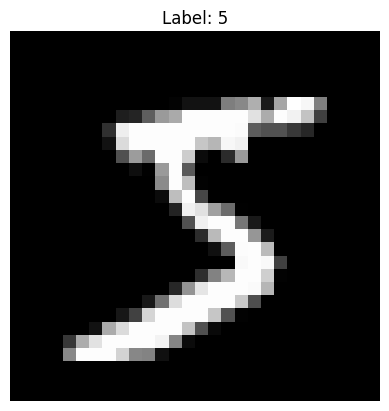

In [8]:
plt.imshow(x_train[0], cmap='gray')
plt.title(f"Label: {y_train[0]}")
plt.axis('off')
plt.show()

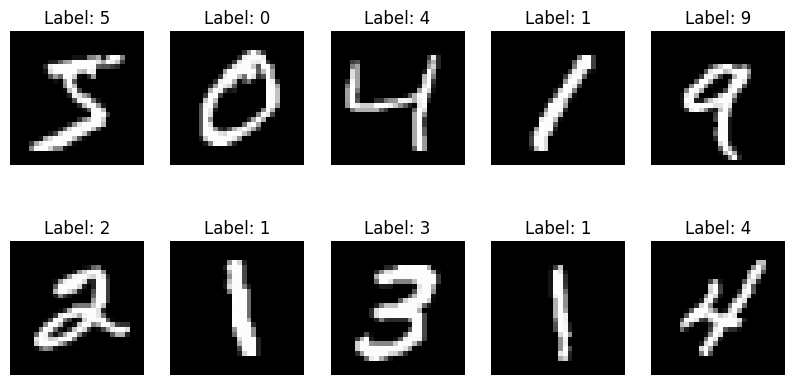

In [9]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.show()

In [10]:
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Minimum pixel value: 0
Maximum pixel value: 255


In [11]:
x_train = x_train / 255.0
x_test = x_test / 255.0

In [12]:
print(x_train.min())
print(x_train.max())

0.0
1.0


In [15]:
model = Sequential([
    Flatten(input_shape=(28, 28)),

    Dense(128, activation='relu'),

    Dense(10, activation='softmax')
])

In [16]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [18]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9227 - loss: 0.2695 - val_accuracy: 0.9685 - val_loss: 0.1257
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9635 - loss: 0.1212 - val_accuracy: 0.9705 - val_loss: 0.1039
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9749 - loss: 0.0836 - val_accuracy: 0.9772 - val_loss: 0.0869
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9813 - loss: 0.0612 - val_accuracy: 0.9778 - val_loss: 0.0814
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9849 - loss: 0.0487 - val_accuracy: 0.9773 - val_loss: 0.0772
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9885 - loss: 0.0368 - val_accuracy: 0.9797 - val_loss: 0.0790
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9908 - loss: 0.0294 - val_accuracy: 0.9802 - val_loss: 0.0803
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9931 - loss: 0.0231 - 

In [19]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9777 - loss: 0.0838
Test Loss: 0.08380602300167084
Test Accuracy: 0.9776999950408936


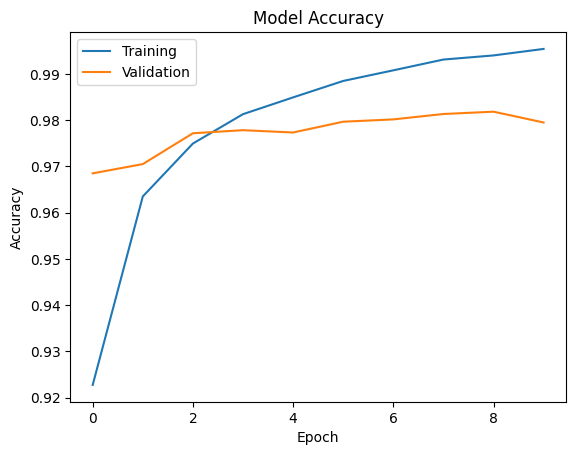

In [20]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend(['Training', 'Validation'])
plt.show()

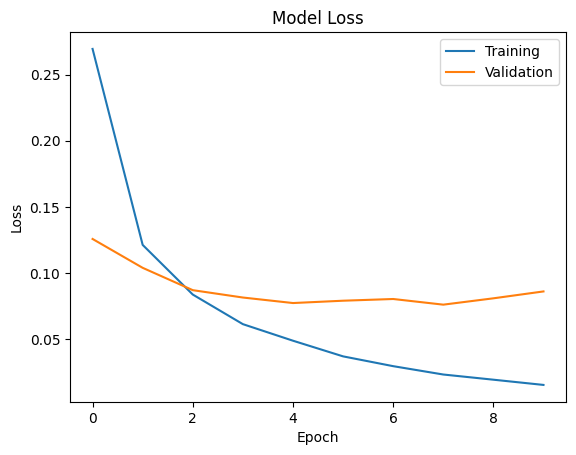

In [21]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend(['Training', 'Validation'])
plt.show()

In [22]:
predictions = model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


In [23]:
print(predictions[0])

[2.8397949e-07 1.0586434e-10 6.0575127e-07 2.2752586e-04 4.0834323e-16
 3.6244796e-10 2.1081471e-15 9.9958986e-01 2.1664616e-07 1.8153840e-04]


In [24]:
predicted_digit = np.argmax(predictions[0])

print("Predicted:", predicted_digit)
print("Actual:", y_test[0])

Predicted: 7
Actual: 7


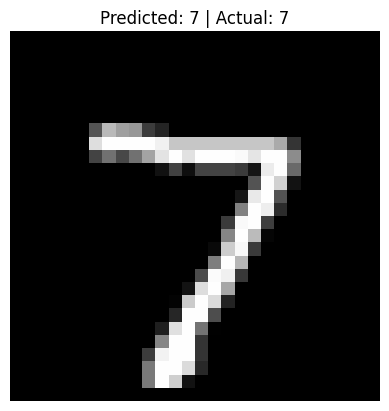

In [25]:
plt.imshow(x_test[0], cmap='gray')

plt.title(
    f"Predicted: {np.argmax(predictions[0])} | Actual: {y_test[0]}"
)

plt.axis('off')
plt.show()

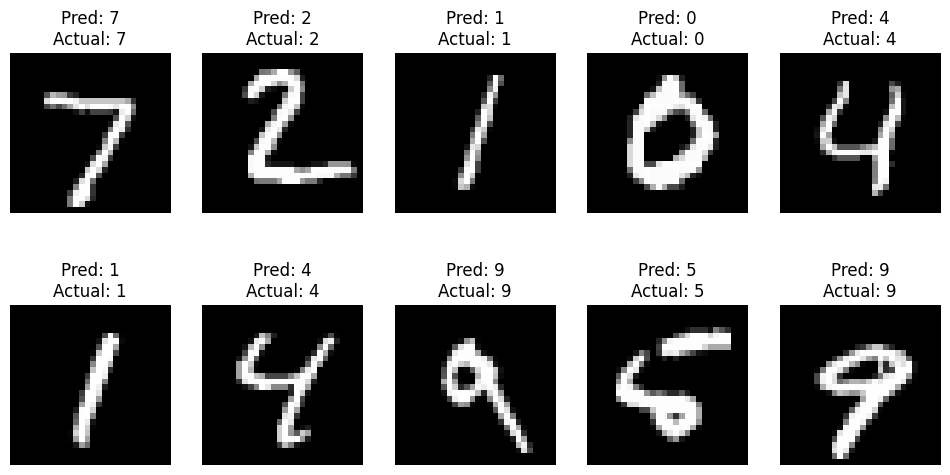

In [26]:
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(x_test[i], cmap='gray')

    predicted = np.argmax(predictions[i])

    plt.title(f"Pred: {predicted}\nActual: {y_test[i]}")
    plt.axis('off')

plt.show()

In [27]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

In [28]:
y_pred = np.argmax(predictions, axis=1)

In [29]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[ 976    1    1    0    0    0    0    1    1    0]
 [   1 1125    3    1    0    0    2    1    2    0]
 [   9    2 1009    0    2    0    2    3    5    0]
 [   2    0    3  984    0    1    1    8    7    4]
 [   7    0    1    1  953    1    5    4    2    8]
 [   5    0    0   15    1  854    5    2    7    3]
 [   6    2    0    1    3    2  942    0    2    0]
 [   2    4    8    1    0    0    0 1002    6    5]
 [   6    1    3    4    1    0    2    3  950    4]
 [   4    3    1    0    5    1    1    9    3  982]]


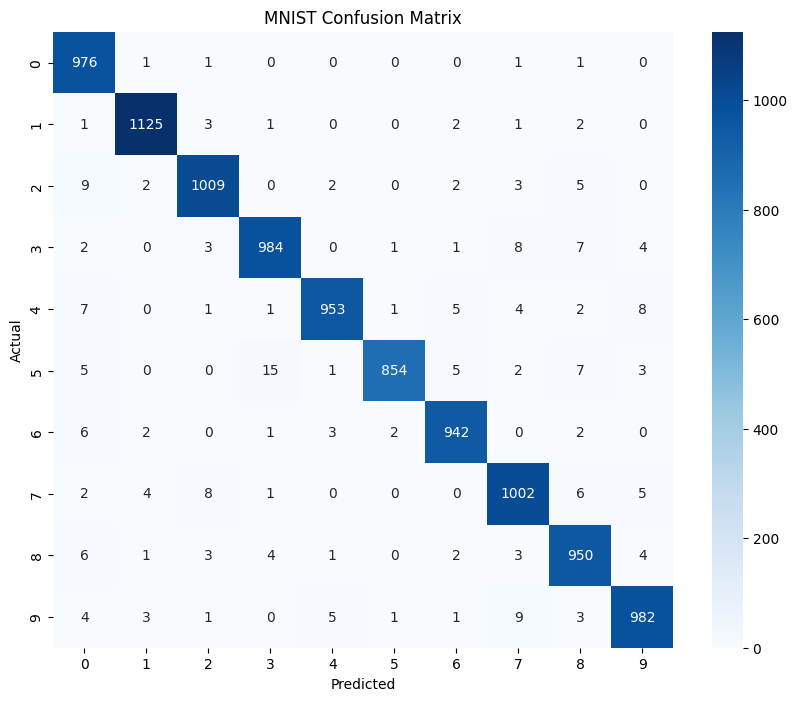

In [30]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('MNIST Confusion Matrix')

plt.show()